In [111]:
import pandas as pd 
import numpy as np 

***It's a Appointment Dataset***


In [112]:
#Records patient registration dates and times, appointment schedules, and actual arrival times. 
#It helps analyze registration duration, appointment delays, and the difference between scheduled and actual arrival times.

In [113]:
df=pd.read_csv("appointments_registration.csv")
df

,Case_ID,Registration_Date,Registration_Start_Time,Registration_End_Time,Appointment_Date,Appointment_Time,Actual_Arrival_Time,Registration_Duration_Minutes,Arrival_vs_Appointment_Minutes
0,P0001,2026-10-01,2026-10-01 18:39:00,2026-10-01 18:41:00,NaN,NaN,2026-10-01 18:39:00,2.0,NaN
1,P0002,2026-10-10,2026-10-10 18:21:00,2026-10-10 18:29:00,NaN,NaN,2026-10-10 18:21:00,8.0,NaN
2,P0003,2026-10-03,2026-10-03 08:26:00,2026-10-03 08:31:00,NaN,NaN,2026-10-03 08:26:00,5.0,NaN
3,P0004,2026-10-02,2026-10-02 15:30:00,2026-10-02 15:38:00,NaN,NaN,2026-10-02 15:30:00,8.0,NaN
4,P0005,2026-10-03,2026-10-03 08:05:00,2026-10-03 08:13:00,NaN,NaN,2026-10-03 08:05:00,8.0,NaN
...,...,...,...,...,...,...,...,...,...
495,P0496,2026-10-03,2026-10-03 17:58:00,2026-10-03 18:10:00,NaN,NaN,2026-10-03 17:58:00,12.0,NaN
496,P0497,2026-10-02,2026-10-02 20:37:00,2026-10-02 20:42:00,NaN,NaN,2026-10-02 20:37:00,5.0,NaN
497,P0498,2026-10-06,2026-10-06 11:55:00,2026-10-06 11:58:00,NaN,NaN,2026-10-06 11:55:00,3.0,NaN
498,P0499,2026-10-06,2026-10-06 10:05:00,2026-10-06 10:19:00,NaN,NaN,2026-10-06 10:05:00,14.0,NaN


In [114]:
df.head

<bound method NDFrame.head of     Case_ID Registration_Date Registration_Start_Time Registration_End_Time  \
0     P0001        2026-10-01     2026-10-01 18:39:00   2026-10-01 18:41:00   
1     P0002        2026-10-10     2026-10-10 18:21:00   2026-10-10 18:29:00   
2     P0003        2026-10-03     2026-10-03 08:26:00   2026-10-03 08:31:00   
3     P0004        2026-10-02     2026-10-02 15:30:00   2026-10-02 15:38:00   
4     P0005        2026-10-03     2026-10-03 08:05:00   2026-10-03 08:13:00   
..      ...               ...                     ...                   ...   
495   P0496        2026-10-03     2026-10-03 17:58:00   2026-10-03 18:10:00   
496   P0497        2026-10-02     2026-10-02 20:37:00   2026-10-02 20:42:00   
497   P0498        2026-10-06     2026-10-06 11:55:00   2026-10-06 11:58:00   
498   P0499        2026-10-06     2026-10-06 10:05:00   2026-10-06 10:19:00   
499   P0500        2026-10-07     2026-10-07 18:01:00   2026-10-07 18:09:00   

    Appointment_Date 

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Case_ID                         500 non-null    str    
 1   Registration_Date               500 non-null    str    
 2   Registration_Start_Time         500 non-null    str    
 3   Registration_End_Time           500 non-null    str    
 4   Appointment_Date                132 non-null    str    
 5   Appointment_Time                132 non-null    str    
 6   Actual_Arrival_Time             500 non-null    str    
 7   Registration_Duration_Minutes   500 non-null    float64
 8   Arrival_vs_Appointment_Minutes  132 non-null    float64
dtypes: float64(2), str(7)
memory usage: 74.3 KB


In [116]:
df_clean = df.copy()

In [117]:
df_clean.head()

,Case_ID,Registration_Date,Registration_Start_Time,Registration_End_Time,Appointment_Date,Appointment_Time,Actual_Arrival_Time,Registration_Duration_Minutes,Arrival_vs_Appointment_Minutes
0,P0001,2026-10-01,2026-10-01 18:39:00,2026-10-01 18:41:00,NaN,NaN,2026-10-01 18:39:00,2.0,NaN
1,P0002,2026-10-10,2026-10-10 18:21:00,2026-10-10 18:29:00,NaN,NaN,2026-10-10 18:21:00,8.0,NaN
2,P0003,2026-10-03,2026-10-03 08:26:00,2026-10-03 08:31:00,NaN,NaN,2026-10-03 08:26:00,5.0,NaN
3,P0004,2026-10-02,2026-10-02 15:30:00,2026-10-02 15:38:00,NaN,NaN,2026-10-02 15:30:00,8.0,NaN
4,P0005,2026-10-03,2026-10-03 08:05:00,2026-10-03 08:13:00,NaN,NaN,2026-10-03 08:05:00,8.0,NaN


In [118]:
missing_percentage= df_clean.isnull().mean()*100
missing_percentage

Case_ID                            0.0
Registration_Date                  0.0
Registration_Start_Time            0.0
Registration_End_Time              0.0
Appointment_Date                  73.6
Appointment_Time                  73.6
Actual_Arrival_Time                0.0
Registration_Duration_Minutes      0.0
Arrival_vs_Appointment_Minutes    73.6
dtype: float64

In [119]:
df_clean.dtypes

Case_ID                               str
Registration_Date                     str
Registration_Start_Time               str
Registration_End_Time                 str
Appointment_Date                      str
Appointment_Time                      str
Actual_Arrival_Time                   str
Registration_Duration_Minutes     float64
Arrival_vs_Appointment_Minutes    float64
dtype: object

In [120]:
df_clean[[
    "Registration_Date",
    "Registration_Start_Time",
    "Appointment_Date",
    "Appointment_Time",
    "Actual_Arrival_Time"
]].head(20)

,Registration_Date,Registration_Start_Time,Appointment_Date,Appointment_Time,Actual_Arrival_Time
0,2026-10-01,2026-10-01 18:39:00,NaN,NaN,2026-10-01 18:39:00
1,2026-10-10,2026-10-10 18:21:00,NaN,NaN,2026-10-10 18:21:00
2,2026-10-03,2026-10-03 08:26:00,NaN,NaN,2026-10-03 08:26:00
3,2026-10-02,2026-10-02 15:30:00,NaN,NaN,2026-10-02 15:30:00
4,2026-10-03,2026-10-03 08:05:00,NaN,NaN,2026-10-03 08:05:00
5,2026-10-04,2026-10-04 14:46:00,NaN,NaN,2026-10-04 14:46:00
6,2026-10-02,2026-10-02 15:22:00,NaN,NaN,2026-10-02 15:22:00
7,2026-10-08,2026-10-08 20:05:00,2026-10-08,2026-10-08 19:35:00,2026-10-08 20:05:00
8,2026-10-10,2026-10-10 08:17:00,NaN,NaN,2026-10-10 08:17:00
9,2026-10-10,2026-10-10 19:01:00,2026-10-10,2026-10-10 19:10:00,2026-10-10 19:01:00


In [121]:
datetime_columns = [
    "Registration_Date",
    "Registration_Start_Time",
    "Registration_End_Time",
    "Appointment_Date",
    "Appointment_Time",
    "Actual_Arrival_Time"
]

for col in datetime_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

df_clean

,Case_ID,Registration_Date,Registration_Start_Time,Registration_End_Time,Appointment_Date,Appointment_Time,Actual_Arrival_Time,Registration_Duration_Minutes,Arrival_vs_Appointment_Minutes
0,P0001,2026-10-01,2026-10-01 18:39:00,2026-10-01 18:41:00,NaT,NaT,2026-10-01 18:39:00,2.0,NaN
1,P0002,2026-10-10,2026-10-10 18:21:00,2026-10-10 18:29:00,NaT,NaT,2026-10-10 18:21:00,8.0,NaN
2,P0003,2026-10-03,2026-10-03 08:26:00,2026-10-03 08:31:00,NaT,NaT,2026-10-03 08:26:00,5.0,NaN
3,P0004,2026-10-02,2026-10-02 15:30:00,2026-10-02 15:38:00,NaT,NaT,2026-10-02 15:30:00,8.0,NaN
4,P0005,2026-10-03,2026-10-03 08:05:00,2026-10-03 08:13:00,NaT,NaT,2026-10-03 08:05:00,8.0,NaN
...,...,...,...,...,...,...,...,...,...
495,P0496,2026-10-03,2026-10-03 17:58:00,2026-10-03 18:10:00,NaT,NaT,2026-10-03 17:58:00,12.0,NaN
496,P0497,2026-10-02,2026-10-02 20:37:00,2026-10-02 20:42:00,NaT,NaT,2026-10-02 20:37:00,5.0,NaN
497,P0498,2026-10-06,2026-10-06 11:55:00,2026-10-06 11:58:00,NaT,NaT,2026-10-06 11:55:00,3.0,NaN
498,P0499,2026-10-06,2026-10-06 10:05:00,2026-10-06 10:19:00,NaT,NaT,2026-10-06 10:05:00,14.0,NaN


In [122]:
df_clean[datetime_columns].dtypes

Registration_Date          datetime64[us]
Registration_Start_Time    datetime64[us]
Registration_End_Time      datetime64[us]
Appointment_Date           datetime64[us]
Appointment_Time           datetime64[us]
Actual_Arrival_Time        datetime64[us]
dtype: object

In [123]:
df_clean["Registration_Start_Time"] = pd.to_datetime(
    df_clean["Registration_Start_Time"],
    errors="coerce"
)

df_clean["Registration_Start_Time"] = (
    df_clean["Registration_Start_Time"].dt.strftime("%H:%M:%S")
)
df_clean

,Case_ID,Registration_Date,Registration_Start_Time,Registration_End_Time,Appointment_Date,Appointment_Time,Actual_Arrival_Time,Registration_Duration_Minutes,Arrival_vs_Appointment_Minutes
0,P0001,2026-10-01,18:39:00,2026-10-01 18:41:00,NaT,NaT,2026-10-01 18:39:00,2.0,NaN
1,P0002,2026-10-10,18:21:00,2026-10-10 18:29:00,NaT,NaT,2026-10-10 18:21:00,8.0,NaN
2,P0003,2026-10-03,08:26:00,2026-10-03 08:31:00,NaT,NaT,2026-10-03 08:26:00,5.0,NaN
3,P0004,2026-10-02,15:30:00,2026-10-02 15:38:00,NaT,NaT,2026-10-02 15:30:00,8.0,NaN
4,P0005,2026-10-03,08:05:00,2026-10-03 08:13:00,NaT,NaT,2026-10-03 08:05:00,8.0,NaN
...,...,...,...,...,...,...,...,...,...
495,P0496,2026-10-03,17:58:00,2026-10-03 18:10:00,NaT,NaT,2026-10-03 17:58:00,12.0,NaN
496,P0497,2026-10-02,20:37:00,2026-10-02 20:42:00,NaT,NaT,2026-10-02 20:37:00,5.0,NaN
497,P0498,2026-10-06,11:55:00,2026-10-06 11:58:00,NaT,NaT,2026-10-06 11:55:00,3.0,NaN
498,P0499,2026-10-06,10:05:00,2026-10-06 10:19:00,NaT,NaT,2026-10-06 10:05:00,14.0,NaN


In [124]:
df_clean["Registration_End_Time"] = pd.to_datetime(
    df_clean["Registration_End_Time"],
    errors="coerce"
)

df_clean["Registration_End_Time"] = (
    df_clean["Registration_End_Time"].dt.strftime("%H:%M:%S")
)
df_clean

,Case_ID,Registration_Date,Registration_Start_Time,Registration_End_Time,Appointment_Date,Appointment_Time,Actual_Arrival_Time,Registration_Duration_Minutes,Arrival_vs_Appointment_Minutes
0,P0001,2026-10-01,18:39:00,18:41:00,NaT,NaT,2026-10-01 18:39:00,2.0,NaN
1,P0002,2026-10-10,18:21:00,18:29:00,NaT,NaT,2026-10-10 18:21:00,8.0,NaN
2,P0003,2026-10-03,08:26:00,08:31:00,NaT,NaT,2026-10-03 08:26:00,5.0,NaN
3,P0004,2026-10-02,15:30:00,15:38:00,NaT,NaT,2026-10-02 15:30:00,8.0,NaN
4,P0005,2026-10-03,08:05:00,08:13:00,NaT,NaT,2026-10-03 08:05:00,8.0,NaN
...,...,...,...,...,...,...,...,...,...
495,P0496,2026-10-03,17:58:00,18:10:00,NaT,NaT,2026-10-03 17:58:00,12.0,NaN
496,P0497,2026-10-02,20:37:00,20:42:00,NaT,NaT,2026-10-02 20:37:00,5.0,NaN
497,P0498,2026-10-06,11:55:00,11:58:00,NaT,NaT,2026-10-06 11:55:00,3.0,NaN
498,P0499,2026-10-06,10:05:00,10:19:00,NaT,NaT,2026-10-06 10:05:00,14.0,NaN


In [125]:
df_clean[[
    "Registration_Date",
    "Registration_Start_Time",
    "Registration_End_Time"
]].head()

,Registration_Date,Registration_Start_Time,Registration_End_Time
0,2026-10-01,18:39:00,18:41:00
1,2026-10-10,18:21:00,18:29:00
2,2026-10-03,08:26:00,08:31:00
3,2026-10-02,15:30:00,15:38:00
4,2026-10-03,08:05:00,08:13:00


In [126]:
df_clean.to_csv("appointments_registration_cleaned.csv", index=False)


In [127]:
df_clean.isnull().sum()

Case_ID                             0
Registration_Date                   0
Registration_Start_Time             0
Registration_End_Time               0
Appointment_Date                  368
Appointment_Time                  368
Actual_Arrival_Time                 0
Registration_Duration_Minutes       0
Arrival_vs_Appointment_Minutes    368
dtype: int64

In [128]:
df_clean.describe()

,Registration_Date,Appointment_Date,Appointment_Time,Actual_Arrival_Time,Registration_Duration_Minutes,Arrival_vs_Appointment_Minutes
count,500,132,132,500,500.000000,132.000000
mean,2026-10-05 12:00:00,2026-10-05 12:43:38.181818,2026-10-06 02:46:38.636363,2026-10-06 02:08:47.760000,6.676000,14.742424
min,2026-10-01 00:00:00,2026-10-01 00:00:00,2026-10-01 06:35:00,2026-10-01 07:05:00,2.000000,-15.000000
25%,2026-10-03 00:00:00,2026-10-03 00:00:00,2026-10-03 16:14:30,2026-10-03 13:37:00,4.000000,0.000000
50%,2026-10-05 00:00:00,2026-10-05 00:00:00,2026-10-05 18:43:00,2026-10-05 20:16:00,7.000000,14.500000
75%,2026-10-08 00:00:00,2026-10-08 00:00:00,2026-10-08 16:17:30,2026-10-08 15:18:15,9.000000,30.250000
max,2026-10-10 00:00:00,2026-10-10 00:00:00,2026-10-10 20:58:00,2026-10-10 21:55:00,15.000000,45.000000
std,NaN,NaN,NaN,NaN,2.876033,17.280188


**It is a patient Dataset**

In [129]:
#Contains basic patient information, including Case ID, medical condition, priority level, patient type, department, and age group.
#It describes which patients are visiting the hospital and what type of care they require.

In [130]:
pa=pd.read_csv("patient.csv")
pa

,Case_ID,Condition,Patient_Priority,Patient_Type,Department,Age_Group
0,P0001,Breathing_Issue,Urgent,Walk_In,Emergency,Child
1,P0002,Chest_Pain,Routine,Walk_In,Emergency,Child
2,P0003,Headache,Routine,Walk_In,Emergency,Child
3,P0004,Headache,Urgent,Walk_In,Emergency,Child
4,P0005,Breathing_Issue,Routine,Walk_In,Emergency,Child
...,...,...,...,...,...,...
495,P0496,Chest_Pain,Routine,Walk_In,Emergency,Child
496,P0497,Headache,Routine,Walk_In,Emergency,Adult
497,P0498,Abdominal_Pain,Routine,Walk_In,Emergency,Child
498,P0499,Injury,Emergency,Walk_In,Emergency,Child


In [131]:
pa.head()

,Case_ID,Condition,Patient_Priority,Patient_Type,Department,Age_Group
0,P0001,Breathing_Issue,Urgent,Walk_In,Emergency,Child
1,P0002,Chest_Pain,Routine,Walk_In,Emergency,Child
2,P0003,Headache,Routine,Walk_In,Emergency,Child
3,P0004,Headache,Urgent,Walk_In,Emergency,Child
4,P0005,Breathing_Issue,Routine,Walk_In,Emergency,Child


In [132]:
pa.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Case_ID           500 non-null    str  
 1   Condition         500 non-null    str  
 2   Patient_Priority  500 non-null    str  
 3   Patient_Type      500 non-null    str  
 4   Department        500 non-null    str  
 5   Age_Group         500 non-null    str  
dtypes: str(6)
memory usage: 45.0 KB


In [133]:
pa.shape

(500, 6)

In [134]:
pa.isnull().sum()

Case_ID             0
Condition           0
Patient_Priority    0
Patient_Type        0
Department          0
Age_Group           0
dtype: int64

In [135]:
pa.describe()

,Case_ID,Condition,Patient_Priority,Patient_Type,Department,Age_Group
count,500,500,500,500,500,500
unique,500,6,3,2,1,3
top,P0001,Fever,Routine,Walk_In,Emergency,Child
freq,1,92,294,368,500,175


In [136]:
pa.duplicated().sum()

np.int64(0)

**Doctor Status**

In [137]:
#Records timestamped doctor-status observations, such as being in consultation or available. 
#It helps examine doctor availability and consultation periods; however, these simulated observations do not necessarily represent continuous, real-time availability.

In [138]:
doc=pd.read_csv("doctor_status_log.csv") 
doc

,Case_ID,Doctor_ID,Timestamp,Status
0,P0255,D01,2026-10-01 11:06:00,In_Consultation
1,P0255,D01,2026-10-01 11:18:00,Available
2,P0082,D01,2026-10-01 12:38:00,In_Consultation
3,P0082,D01,2026-10-01 12:46:00,Available
4,P0247,D01,2026-10-01 14:55:00,In_Consultation
...,...,...,...,...
995,P0418,D12,2026-10-10 18:27:00,Available
996,P0404,D12,2026-10-10 19:26:00,In_Consultation
997,P0404,D12,2026-10-10 19:36:00,Available
998,P0406,D12,2026-10-10 20:20:00,In_Consultation


In [139]:
doc.head()

,Case_ID,Doctor_ID,Timestamp,Status
0,P0255,D01,2026-10-01 11:06:00,In_Consultation
1,P0255,D01,2026-10-01 11:18:00,Available
2,P0082,D01,2026-10-01 12:38:00,In_Consultation
3,P0082,D01,2026-10-01 12:46:00,Available
4,P0247,D01,2026-10-01 14:55:00,In_Consultation


In [140]:
doc.shape

(1000, 4)

In [141]:
doc.isnull().sum()

Case_ID      0
Doctor_ID    0
Timestamp    0
Status       0
dtype: int64

In [142]:
doc.duplicated().sum()

np.int64(0)

In [143]:
doc.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Case_ID    1000 non-null   str  
 1   Doctor_ID  1000 non-null   str  
 2   Timestamp  1000 non-null   str  
 3   Status     1000 non-null   str  
dtypes: str(4)
memory usage: 69.5 KB


In [144]:
doc.describe()

,Case_ID,Doctor_ID,Timestamp,Status
count,1000,1000,1000,1000
unique,500,8,945,2
top,P0255,D12,2026-10-05 08:06:00,In_Consultation
freq,2,140,3,500


**It is patient event Dataset**

In [145]:
#Contains each patient's activities, timestamps, departments, and associated doctor IDs. 
#It describes the sequence of steps followed by each patient, helping identify waiting times, process bottlenecks, and different patient pathways.

In [146]:
event=pd.read_csv("patient_event_log.csv") 
event

,Case_ID,Activity_Name,Timestamp,Doctor_ID,Department,Previous_Activity,Previous_Timestamp,Gap_Minutes_From_Previous_Activity
0,P0001,Registration,2026-10-01 18:39:00,NaN,Registration,NaN,NaN,NaN
1,P0001,Triage,2026-10-01 18:50:00,NaN,Emergency,Registration,2026-10-01 18:39:00,11.0
2,P0001,Doctor_Consultation,2026-10-01 19:17:00,D11,Emergency,Triage,2026-10-01 18:50:00,27.0
3,P0001,Laboratory,2026-10-01 19:44:00,NaN,Laboratory,Doctor_Consultation,2026-10-01 19:17:00,27.0
4,P0001,Discharge,2026-10-01 20:25:00,D11,Emergency,Laboratory,2026-10-01 19:44:00,41.0
...,...,...,...,...,...,...,...,...
2602,P0500,Triage,2026-10-07 18:19:00,NaN,Emergency,Registration,2026-10-07 18:01:00,18.0
2603,P0500,Doctor_Consultation,2026-10-07 19:02:00,D06,Emergency,Triage,2026-10-07 18:19:00,43.0
2604,P0500,X_Ray,2026-10-07 20:04:00,NaN,X_Ray,Doctor_Consultation,2026-10-07 19:02:00,62.0
2605,P0500,Doctor_Review,2026-10-07 20:29:00,D06,Emergency,X_Ray,2026-10-07 20:04:00,25.0


In [147]:
event.head()

,Case_ID,Activity_Name,Timestamp,Doctor_ID,Department,Previous_Activity,Previous_Timestamp,Gap_Minutes_From_Previous_Activity
0,P0001,Registration,2026-10-01 18:39:00,NaN,Registration,NaN,NaN,NaN
1,P0001,Triage,2026-10-01 18:50:00,NaN,Emergency,Registration,2026-10-01 18:39:00,11.0
2,P0001,Doctor_Consultation,2026-10-01 19:17:00,D11,Emergency,Triage,2026-10-01 18:50:00,27.0
3,P0001,Laboratory,2026-10-01 19:44:00,NaN,Laboratory,Doctor_Consultation,2026-10-01 19:17:00,27.0
4,P0001,Discharge,2026-10-01 20:25:00,D11,Emergency,Laboratory,2026-10-01 19:44:00,41.0


In [148]:
event.shape

(2607, 8)

In [149]:
event.info()

<class 'pandas.DataFrame'>
RangeIndex: 2607 entries, 0 to 2606
Data columns (total 8 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Case_ID                             2607 non-null   str    
 1   Activity_Name                       2607 non-null   str    
 2   Timestamp                           2607 non-null   str    
 3   Doctor_ID                           1182 non-null   str    
 4   Department                          2607 non-null   str    
 5   Previous_Activity                   2107 non-null   str    
 6   Previous_Timestamp                  2107 non-null   str    
 7   Gap_Minutes_From_Previous_Activity  2107 non-null   float64
dtypes: float64(1), str(7)
memory usage: 344.2 KB


In [150]:
event.isnull().sum()

Case_ID                                  0
Activity_Name                            0
Timestamp                                0
Doctor_ID                             1425
Department                               0
Previous_Activity                      500
Previous_Timestamp                     500
Gap_Minutes_From_Previous_Activity     500
dtype: int64

In [151]:
event_clean = event.copy()

In [152]:
event_clean.head(20)

,Case_ID,Activity_Name,Timestamp,Doctor_ID,Department,Previous_Activity,Previous_Timestamp,Gap_Minutes_From_Previous_Activity
0,P0001,Registration,2026-10-01 18:39:00,NaN,Registration,NaN,NaN,NaN
1,P0001,Triage,2026-10-01 18:50:00,NaN,Emergency,Registration,2026-10-01 18:39:00,11.0
2,P0001,Doctor_Consultation,2026-10-01 19:17:00,D11,Emergency,Triage,2026-10-01 18:50:00,27.0
3,P0001,Laboratory,2026-10-01 19:44:00,NaN,Laboratory,Doctor_Consultation,2026-10-01 19:17:00,27.0
4,P0001,Discharge,2026-10-01 20:25:00,D11,Emergency,Laboratory,2026-10-01 19:44:00,41.0
5,P0002,Registration,2026-10-10 18:21:00,NaN,Registration,NaN,NaN,NaN
6,P0002,Triage,2026-10-10 18:35:00,NaN,Emergency,Registration,2026-10-10 18:21:00,14.0
7,P0002,Doctor_Consultation,2026-10-10 19:07:00,D02,Emergency,Triage,2026-10-10 18:35:00,32.0
8,P0002,X_Ray,2026-10-10 19:42:00,NaN,X_Ray,Doctor_Consultation,2026-10-10 19:07:00,35.0
9,P0002,Discharge,2026-10-10 20:12:00,D02,Emergency,X_Ray,2026-10-10 19:42:00,30.0


In [153]:
event_clean.isnull().mean()*100

Case_ID                                0.000000
Activity_Name                          0.000000
Timestamp                              0.000000
Doctor_ID                             54.660529
Department                             0.000000
Previous_Activity                     19.179133
Previous_Timestamp                    19.179133
Gap_Minutes_From_Previous_Activity    19.179133
dtype: float64

In [154]:
event_clean = event_clean.sort_values(
    by=["Case_ID", "Timestamp"]
).reset_index(drop=True)
event_clean

,Case_ID,Activity_Name,Timestamp,Doctor_ID,Department,Previous_Activity,Previous_Timestamp,Gap_Minutes_From_Previous_Activity
0,P0001,Registration,2026-10-01 18:39:00,NaN,Registration,NaN,NaN,NaN
1,P0001,Triage,2026-10-01 18:50:00,NaN,Emergency,Registration,2026-10-01 18:39:00,11.0
2,P0001,Doctor_Consultation,2026-10-01 19:17:00,D11,Emergency,Triage,2026-10-01 18:50:00,27.0
3,P0001,Laboratory,2026-10-01 19:44:00,NaN,Laboratory,Doctor_Consultation,2026-10-01 19:17:00,27.0
4,P0001,Discharge,2026-10-01 20:25:00,D11,Emergency,Laboratory,2026-10-01 19:44:00,41.0
...,...,...,...,...,...,...,...,...
2602,P0500,Triage,2026-10-07 18:19:00,NaN,Emergency,Registration,2026-10-07 18:01:00,18.0
2603,P0500,Doctor_Consultation,2026-10-07 19:02:00,D06,Emergency,Triage,2026-10-07 18:19:00,43.0
2604,P0500,X_Ray,2026-10-07 20:04:00,NaN,X_Ray,Doctor_Consultation,2026-10-07 19:02:00,62.0
2605,P0500,Doctor_Review,2026-10-07 20:29:00,D06,Emergency,X_Ray,2026-10-07 20:04:00,25.0


In [155]:
event_clean["Expected_Previous_Activity"] = (
    event_clean.groupby("Case_ID")["Activity_Name"].shift(1)
)

event_clean[
    
    ["Case_ID", "Activity_Name", "Previous_Activity",
     "Expected_Previous_Activity"]
].head(15)

,Case_ID,Activity_Name,Previous_Activity,Expected_Previous_Activity
0,P0001,Registration,NaN,NaN
1,P0001,Triage,Registration,Registration
2,P0001,Doctor_Consultation,Triage,Triage
3,P0001,Laboratory,Doctor_Consultation,Doctor_Consultation
4,P0001,Discharge,Laboratory,Laboratory
5,P0002,Registration,NaN,NaN
6,P0002,Triage,Registration,Registration
7,P0002,Doctor_Consultation,Triage,Triage
8,P0002,X_Ray,Doctor_Consultation,Doctor_Consultation
9,P0002,Discharge,X_Ray,X_Ray


In [156]:
event_clean[
    ["Case_ID", "Activity_Name",
     "Previous_Activity", "Expected_Previous_Activity"]
].head(10)

,Case_ID,Activity_Name,Previous_Activity,Expected_Previous_Activity
0,P0001,Registration,NaN,NaN
1,P0001,Triage,Registration,Registration
2,P0001,Doctor_Consultation,Triage,Triage
3,P0001,Laboratory,Doctor_Consultation,Doctor_Consultation
4,P0001,Discharge,Laboratory,Laboratory
5,P0002,Registration,NaN,NaN
6,P0002,Triage,Registration,Registration
7,P0002,Doctor_Consultation,Triage,Triage
8,P0002,X_Ray,Doctor_Consultation,Doctor_Consultation
9,P0002,Discharge,X_Ray,X_Ray


In [157]:
for case_id, group in event_clean.groupby("Case_ID"):
    activities = group["Activity_Name"].tolist()
    print(case_id, " → ".join(activities))

P0001 Registration → Triage → Doctor_Consultation → Laboratory → Discharge
P0002 Registration → Triage → Doctor_Consultation → X_Ray → Discharge
P0003 Registration → Triage → Doctor_Consultation → Discharge
P0004 Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission
P0005 Registration → Triage → Doctor_Consultation → X_Ray → Discharge
P0006 Registration → Triage → Doctor_Consultation → Laboratory → Discharge
P0007 Registration → Triage → Doctor_Consultation → Discharge
P0008 Registration → Triage → Doctor_Consultation → Discharge
P0009 Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge
P0010 Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge
P0011 Registration → Triage → Doctor_Consultation → X_Ray → Discharge
P0012 Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge
P0013 Registration → Triage → Doctor_Consultation → Discharge
P0014 Registration → Triage → Doc

In [158]:
event.duplicated().sum()

np.int64(0)

In [159]:
event.describe()

,Gap_Minutes_From_Previous_Activity
count,2107.000000
mean,25.802563
std,15.582118
min,3.000000
25%,16.000000
50%,23.000000
75%,33.000000
max,162.000000


**Doctor Information**

In [160]:
#Stores doctor details such as Doctor ID, specialty, department, and assigned shift. 
#It helps understand which doctors are associated with which departments and shifts.

In [161]:
d=pd.read_csv("doctors_master.csv")                  
d

,Doctor_ID,Specialty,Department,Shift_Start,Shift_End
0,D01,Emergency_Medicine,Emergency,08:00,16:00
1,D02,Emergency_Medicine,Emergency,08:00,16:00
2,D03,General_Medicine,General_Medicine,08:00,16:00
3,D04,General_Medicine,General_Medicine,12:00,20:00
4,D05,General_Medicine,General_Medicine,08:00,16:00
5,D06,Emergency_Medicine,Emergency,16:00,00:00
6,D07,Radiology,Radiology,08:00,16:00
7,D08,Radiology,Radiology,12:00,20:00
8,D09,Laboratory,Laboratory,08:00,16:00
9,D10,Laboratory,Laboratory,12:00,20:00


In [162]:
d.head()

,Doctor_ID,Specialty,Department,Shift_Start,Shift_End
0,D01,Emergency_Medicine,Emergency,08:00,16:00
1,D02,Emergency_Medicine,Emergency,08:00,16:00
2,D03,General_Medicine,General_Medicine,08:00,16:00
3,D04,General_Medicine,General_Medicine,12:00,20:00
4,D05,General_Medicine,General_Medicine,08:00,16:00


In [163]:
d.shape

(12, 5)

In [164]:
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Doctor_ID    12 non-null     str  
 1   Specialty    12 non-null     str  
 2   Department   12 non-null     str  
 3   Shift_Start  12 non-null     str  
 4   Shift_End    12 non-null     str  
dtypes: str(5)
memory usage: 1.1 KB


In [165]:
d.isnull().sum()

Doctor_ID      0
Specialty      0
Department     0
Shift_Start    0
Shift_End      0
dtype: int64

In [166]:
d.duplicated().sum()

np.int64(0)

In [167]:
d.describe()

,Doctor_ID,Specialty,Department,Shift_Start,Shift_End
count,12,12,12,12,12
unique,12,4,4,3,3
top,D01,Emergency_Medicine,Emergency,08:00,16:00
freq,1,4,4,6,6


**Operational Factor**

In [168]:
#Contains operational observations such as queue length, doctor status, staff availability, document status, test availability, equipment status, and bed status. 
#It helps explore which operational conditions may be associated with patient delays.

In [169]:
op=pd.read_csv("operational_factors.csv") 
op

,Case_ID,Queue_Length_At_Triage,Doctor_Status_At_Consult_Start,Staff_Status,Document_Status,Test_Type,Test_Status,Equipment_Status,Bed_Status
0,P0001,9,Busy,Adequate,Complete,Laboratory,Normal,Available,Not_Applicable
1,P0002,8,Available,Adequate,Complete,X_Ray,Normal,Available,Not_Applicable
2,P0003,2,Busy,Adequate,Complete,NaN,Not_Required,Not_Required,Not_Applicable
3,P0004,3,Available,Adequate,Complete,Laboratory,Normal,Available,Unavailable
4,P0005,8,Busy,Adequate,Complete,X_Ray,Normal,Unavailable,Not_Applicable
...,...,...,...,...,...,...,...,...,...
495,P0496,8,Available,Adequate,Complete,X_Ray,Backlog,Available,Available
496,P0497,3,Busy,Short_Staffed,Complete,Laboratory,Backlog,Available,Not_Applicable
497,P0498,5,Busy,Adequate,Complete,Laboratory,Normal,Available,Not_Applicable
498,P0499,6,Available,Short_Staffed,Incomplete,X_Ray,Normal,Available,Not_Applicable


In [170]:
op.head(10)

,Case_ID,Queue_Length_At_Triage,Doctor_Status_At_Consult_Start,Staff_Status,Document_Status,Test_Type,Test_Status,Equipment_Status,Bed_Status
0,P0001,9,Busy,Adequate,Complete,Laboratory,Normal,Available,Not_Applicable
1,P0002,8,Available,Adequate,Complete,X_Ray,Normal,Available,Not_Applicable
2,P0003,2,Busy,Adequate,Complete,NaN,Not_Required,Not_Required,Not_Applicable
3,P0004,3,Available,Adequate,Complete,Laboratory,Normal,Available,Unavailable
4,P0005,8,Busy,Adequate,Complete,X_Ray,Normal,Unavailable,Not_Applicable
5,P0006,5,Busy,Short_Staffed,Complete,Laboratory,Normal,Available,Not_Applicable
6,P0007,4,Busy,Adequate,Complete,NaN,Not_Required,Not_Required,Not_Applicable
7,P0008,4,Busy,Adequate,Complete,NaN,Not_Required,Not_Required,Not_Applicable
8,P0009,4,Available,Short_Staffed,Complete,X_Ray,Backlog,Available,Not_Applicable
9,P0010,8,Busy,Adequate,Complete,Laboratory,Normal,Available,Not_Applicable


In [171]:
op.shape

(500, 9)

In [172]:
op.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype
---  ------                          --------------  -----
 0   Case_ID                         500 non-null    str  
 1   Queue_Length_At_Triage          500 non-null    int64
 2   Doctor_Status_At_Consult_Start  500 non-null    str  
 3   Staff_Status                    500 non-null    str  
 4   Document_Status                 500 non-null    str  
 5   Test_Type                       351 non-null    str  
 6   Test_Status                     500 non-null    str  
 7   Equipment_Status                500 non-null    str  
 8   Bed_Status                      500 non-null    str  
dtypes: int64(1), str(8)
memory usage: 66.8 KB


In [173]:
op.isnull().sum()

Case_ID                             0
Queue_Length_At_Triage              0
Doctor_Status_At_Consult_Start      0
Staff_Status                        0
Document_Status                     0
Test_Type                         149
Test_Status                         0
Equipment_Status                    0
Bed_Status                          0
dtype: int64

In [174]:
op.describe()

,Queue_Length_At_Triage
count,500.000000
mean,5.466000
std,2.379952
min,0.000000
25%,4.000000
50%,5.000000
75%,7.000000
max,15.000000


In [175]:
op.duplicated().sum()

np.int64(0)

In [176]:
op_clean = op.copy()

In [177]:
op_clean.isnull().mean()*100

Case_ID                            0.0
Queue_Length_At_Triage             0.0
Doctor_Status_At_Consult_Start     0.0
Staff_Status                       0.0
Document_Status                    0.0
Test_Type                         29.8
Test_Status                        0.0
Equipment_Status                   0.0
Bed_Status                         0.0
dtype: float64

In [178]:
print(event_clean.columns.tolist())
print(event_clean.head())

['Case_ID', 'Activity_Name', 'Timestamp', 'Doctor_ID', 'Department', 'Previous_Activity', 'Previous_Timestamp', 'Gap_Minutes_From_Previous_Activity', 'Expected_Previous_Activity']
  Case_ID        Activity_Name            Timestamp Doctor_ID    Department  \
0   P0001         Registration  2026-10-01 18:39:00       NaN  Registration   
1   P0001               Triage  2026-10-01 18:50:00       NaN     Emergency   
2   P0001  Doctor_Consultation  2026-10-01 19:17:00       D11     Emergency   
3   P0001           Laboratory  2026-10-01 19:44:00       NaN    Laboratory   
4   P0001            Discharge  2026-10-01 20:25:00       D11     Emergency   

     Previous_Activity   Previous_Timestamp  \
0                  NaN                  NaN   
1         Registration  2026-10-01 18:39:00   
2               Triage  2026-10-01 18:50:00   
3  Doctor_Consultation  2026-10-01 19:17:00   
4           Laboratory  2026-10-01 19:44:00   

   Gap_Minutes_From_Previous_Activity Expected_Previous_Activi

In [179]:
comparison = (
    event_clean["Previous_Activity"].fillna("")
    == event_clean["Expected_Previous_Activity"].fillna("")
)

print(comparison.value_counts())

True    2607
Name: count, dtype: int64


In [180]:
event_clean["Timestamp"] = pd.to_datetime(event_clean["Timestamp"])
event_clean["Previous_Timestamp"] = pd.to_datetime(
    event_clean["Previous_Timestamp"]
)

event_clean["Expected_Previous_Timestamp"] = (
    event_clean.groupby("Case_ID")["Timestamp"].shift(1)
)

comparison_time = (
    event_clean["Previous_Timestamp"].fillna(pd.Timestamp("1900-01-01"))
    == event_clean["Expected_Previous_Timestamp"].fillna(pd.Timestamp("1900-01-01"))
)

print(comparison_time.value_counts())

True    2607
Name: count, dtype: int64


In [181]:
event_clean["Expected_Gap_Minutes"] = (
    event_clean.groupby("Case_ID")["Timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

comparison_gap = (
    event_clean["Gap_Minutes_From_Previous_Activity"].fillna(-1)
    == event_clean["Expected_Gap_Minutes"].fillna(-1)
)

print(comparison_gap.value_counts())

True    2607
Name: count, dtype: int64


In [182]:
event_clean[
    comparison_gap == False
][[
    "Case_ID",
    "Activity_Name",
    "Gap_Minutes_From_Previous_Activity",
    "Expected_Gap_Minutes"
]]

,Case_ID,Activity_Name,Gap_Minutes_From_Previous_Activity,Expected_Gap_Minutes


In [183]:
import pandas as pd

event_clean["Timestamp"] = pd.to_datetime(event_clean["Timestamp"])

event_clean = event_clean.sort_values(
    ["Case_ID", "Timestamp"]
)

activity_flow = (
    event_clean.groupby("Case_ID")["Activity_Name"]
    .apply(lambda x: " → ".join(x))
)

print(activity_flow.head(10))

Case_ID
P0001                    Registration → Triage → Doctor_Consultation → Laboratory → Discharge
P0002                         Registration → Triage → Doctor_Consultation → X_Ray → Discharge
P0003                                 Registration → Triage → Doctor_Consultation → Discharge
P0004    Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission
P0005                         Registration → Triage → Doctor_Consultation → X_Ray → Discharge
P0006                    Registration → Triage → Doctor_Consultation → Laboratory → Discharge
P0007                                 Registration → Triage → Doctor_Consultation → Discharge
P0008                                 Registration → Triage → Doctor_Consultation → Discharge
P0009         Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge
P0010    Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge
Name: Activity_Name, dtype: str


In [184]:
pd.set_option("display.max_colwidth", None)

print(activity_flow.head(10).to_string())

Case_ID
P0001                    Registration → Triage → Doctor_Consultation → Laboratory → Discharge
P0002                         Registration → Triage → Doctor_Consultation → X_Ray → Discharge
P0003                                 Registration → Triage → Doctor_Consultation → Discharge
P0004    Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission
P0005                         Registration → Triage → Doctor_Consultation → X_Ray → Discharge
P0006                    Registration → Triage → Doctor_Consultation → Laboratory → Discharge
P0007                                 Registration → Triage → Doctor_Consultation → Discharge
P0008                                 Registration → Triage → Doctor_Consultation → Discharge
P0009         Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge
P0010    Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge


In [185]:
flow_counts = activity_flow.value_counts()

print(flow_counts.head(10).to_string())

Activity_Name
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge    129
Registration → Triage → Doctor_Consultation → Discharge                                 125
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge          87
Registration → Triage → Doctor_Consultation → Laboratory → Discharge                     58
Registration → Triage → Doctor_Consultation → X_Ray → Discharge                          27
Registration → Triage → Doctor_Consultation → Admission                                  24
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Admission          21
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission     19
Registration → Triage → Doctor_Consultation → Laboratory → Admission                      6
Registration → Triage → Doctor_Consultation → X_Ray → Admission                           4


In [186]:
duplicates = event_clean.duplicated(
    subset=["Case_ID", "Activity_Name", "Timestamp"]
)

print("Duplicate events:", duplicates.sum())

Duplicate events: 0


In [187]:
negative_gaps = event_clean[
    event_clean["Gap_Minutes_From_Previous_Activity"] < 0
]

print("Negative time gaps:", len(negative_gaps))

Negative time gaps: 0


In [188]:
event_clean.isnull().sum()

Case_ID                                  0
Activity_Name                            0
Timestamp                                0
Doctor_ID                             1425
Department                               0
Previous_Activity                      500
Previous_Timestamp                     500
Gap_Minutes_From_Previous_Activity     500
Expected_Previous_Activity             500
Expected_Previous_Timestamp            500
Expected_Gap_Minutes                   500
dtype: int64

In [189]:
event_clean.groupby("Activity_Name")["Doctor_ID"].agg(
    Total_Rows="size",
    Missing_Doctor_ID=lambda x: x.isna().sum()
)

,Total_Rows,Missing_Doctor_ID
Activity_Name,,
Admission,74,74
Discharge,426,0
Doctor_Consultation,500,0
Doctor_Review,256,0
Laboratory,212,212
Registration,500,500
Triage,500,500
X_Ray,139,139


In [190]:
event_clean[
    event_clean["Doctor_ID"].isna()
].groupby("Activity_Name").head(3)[
    ["Case_ID", "Activity_Name", "Timestamp", "Department", "Doctor_ID"]
]

,Case_ID,Activity_Name,Timestamp,Department,Doctor_ID
0,P0001,Registration,2026-10-01 18:39:00,Registration,NaN
1,P0001,Triage,2026-10-01 18:50:00,Emergency,NaN
3,P0001,Laboratory,2026-10-01 19:44:00,Laboratory,NaN
5,P0002,Registration,2026-10-10 18:21:00,Registration,NaN
6,P0002,Triage,2026-10-10 18:35:00,Emergency,NaN
8,P0002,X_Ray,2026-10-10 19:42:00,X_Ray,NaN
10,P0003,Registration,2026-10-03 08:26:00,Registration,NaN
11,P0003,Triage,2026-10-03 08:38:00,Emergency,NaN
17,P0004,Laboratory,2026-10-02 16:34:00,Laboratory,NaN
19,P0004,Admission,2026-10-02 18:07:00,Emergency,NaN


In [191]:
event_clean.groupby("Activity_Name")["Doctor_ID"].agg(
    Total_Rows="size",
    Available_Doctor_ID="count",
    Missing_Doctor_ID="size"
)

,Total_Rows,Available_Doctor_ID,Missing_Doctor_ID
Activity_Name,,,
Admission,74,0,74
Discharge,426,426,426
Doctor_Consultation,500,500,500
Doctor_Review,256,256,256
Laboratory,212,0,212
Registration,500,0,500
Triage,500,0,500
X_Ray,139,0,139


In [192]:
event_clean.groupby("Activity_Name").agg(
    Total_Rows=("Doctor_ID", "size"),
    Available_Doctor_ID=("Doctor_ID", "count"),
    Missing_Doctor_ID=("Doctor_ID", lambda x: x.isna().sum())
)

,Total_Rows,Available_Doctor_ID,Missing_Doctor_ID
Activity_Name,,,
Admission,74,0,74
Discharge,426,426,0
Doctor_Consultation,500,500,0
Doctor_Review,256,256,0
Laboratory,212,0,212
Registration,500,0,500
Triage,500,0,500
X_Ray,139,0,139


In [193]:
event_clean[
    event_clean["Activity_Name"].isin(
        ["Laboratory", "X_Ray", "Admission"]
    )
][["Case_ID", "Activity_Name", "Doctor_ID", "Department"]].head(15)

,Case_ID,Activity_Name,Doctor_ID,Department
3,P0001,Laboratory,NaN,Laboratory
8,P0002,X_Ray,NaN,X_Ray
17,P0004,Laboratory,NaN,Laboratory
19,P0004,Admission,NaN,Emergency
23,P0005,X_Ray,NaN,X_Ray
28,P0006,Laboratory,NaN,Laboratory
41,P0009,X_Ray,NaN,X_Ray
47,P0010,Laboratory,NaN,Laboratory
53,P0011,X_Ray,NaN,X_Ray
58,P0012,Laboratory,NaN,Laboratory


In [194]:
doc.head(10)

,Case_ID,Doctor_ID,Timestamp,Status
0,P0255,D01,2026-10-01 11:06:00,In_Consultation
1,P0255,D01,2026-10-01 11:18:00,Available
2,P0082,D01,2026-10-01 12:38:00,In_Consultation
3,P0082,D01,2026-10-01 12:46:00,Available
4,P0247,D01,2026-10-01 14:55:00,In_Consultation
5,P0247,D01,2026-10-01 15:00:00,Available
6,P0093,D01,2026-10-01 21:38:00,In_Consultation
7,P0093,D01,2026-10-01 21:54:00,Available
8,P0245,D01,2026-10-02 08:16:00,In_Consultation
9,P0245,D01,2026-10-02 08:30:00,Available


In [195]:
d.head(10)

,Doctor_ID,Specialty,Department,Shift_Start,Shift_End
0,D01,Emergency_Medicine,Emergency,08:00,16:00
1,D02,Emergency_Medicine,Emergency,08:00,16:00
2,D03,General_Medicine,General_Medicine,08:00,16:00
3,D04,General_Medicine,General_Medicine,12:00,20:00
4,D05,General_Medicine,General_Medicine,08:00,16:00
5,D06,Emergency_Medicine,Emergency,16:00,00:00
6,D07,Radiology,Radiology,08:00,16:00
7,D08,Radiology,Radiology,12:00,20:00
8,D09,Laboratory,Laboratory,08:00,16:00
9,D10,Laboratory,Laboratory,12:00,20:00


In [196]:
doc.groupby("Doctor_ID").agg(
    Total_Status_Records=("Status", "size"),
    Unique_Statuses=("Status", "nunique")
)

,Total_Status_Records,Unique_Statuses
Doctor_ID,,
D01,120,2
D02,132,2
D03,114,2
D04,126,2
D05,124,2
D06,116,2
D11,128,2
D12,140,2


In [197]:
doc["Status"].value_counts()

Status
In_Consultation    500
Available          500
Name: count, dtype: int64

In [198]:
doc = doc.sort_values(["Doctor_ID", "Timestamp"])

doc[["Case_ID", "Doctor_ID", "Timestamp", "Status"]]

,Case_ID,Doctor_ID,Timestamp,Status
0,P0255,D01,2026-10-01 11:06:00,In_Consultation
1,P0255,D01,2026-10-01 11:18:00,Available
2,P0082,D01,2026-10-01 12:38:00,In_Consultation
3,P0082,D01,2026-10-01 12:46:00,Available
4,P0247,D01,2026-10-01 14:55:00,In_Consultation
...,...,...,...,...
995,P0418,D12,2026-10-10 18:27:00,Available
996,P0404,D12,2026-10-10 19:26:00,In_Consultation
997,P0404,D12,2026-10-10 19:36:00,Available
998,P0406,D12,2026-10-10 20:20:00,In_Consultation


In [199]:
doc["Timestamp"] = pd.to_datetime(doc["Timestamp"], errors="coerce")

In [200]:
print(doc["Timestamp"].dtype)
print("Missing timestamps:", doc["Timestamp"].isna().sum())

datetime64[us]
Missing timestamps: 0


In [201]:
consultation_times = doc.pivot_table(
    index=["Case_ID", "Doctor_ID"],
    columns="Status",
    values="Timestamp",
    aggfunc="min"
)

consultation_times["Consultation_Duration_Minutes"] = (
    consultation_times["Available"]
    - consultation_times["In_Consultation"]
).dt.total_seconds() / 60

consultation_times.head(10)

,Status,Available,In_Consultation,Consultation_Duration_Minutes
Case_ID,Doctor_ID,,,
P0001,D11,2026-10-01 19:24:00,2026-10-01 19:17:00,7.0
P0002,D02,2026-10-10 19:19:00,2026-10-10 19:07:00,12.0
P0003,D05,2026-10-03 09:10:00,2026-10-03 08:59:00,11.0
P0004,D01,2026-10-02 16:22:00,2026-10-02 16:08:00,14.0
P0005,D06,2026-10-03 09:20:00,2026-10-03 09:02:00,18.0
P0006,D03,2026-10-04 15:52:00,2026-10-04 15:41:00,11.0
P0007,D01,2026-10-02 16:25:00,2026-10-02 16:13:00,12.0
P0008,D11,2026-10-08 20:42:00,2026-10-08 20:32:00,10.0
P0009,D06,2026-10-10 09:01:00,2026-10-10 08:47:00,14.0


In [202]:
doctor_summary = consultation_times.groupby(
    level="Doctor_ID"
)["Consultation_Duration_Minutes"].agg(
    Total_Consultations="count",
    Average_Duration="mean",
    Minimum_Duration="min",
    Maximum_Duration="max"
).round(2)

doctor_summary.sort_values(
    "Average_Duration",
    ascending=False
)

,Total_Consultations,Average_Duration,Minimum_Duration,Maximum_Duration
Doctor_ID,,,,
D03,57,12.75,4.0,23.0
D02,66,12.24,4.0,24.0
D06,58,11.86,4.0,20.0
D04,63,11.56,4.0,24.0
D12,70,11.31,4.0,27.0
D01,60,11.28,4.0,22.0
D05,62,10.90,4.0,21.0
D11,64,10.81,4.0,22.0


In [203]:
activity_delay = event_clean.groupby("Activity_Name")[
    "Gap_Minutes_From_Previous_Activity"
].agg(
    Total_Records="count",
    Average_Gap="mean",
    Maximum_Gap="max"
).round(2)

activity_delay.sort_values(
    "Average_Gap",
    ascending=False
)

,Total_Records,Average_Gap,Maximum_Gap
Activity_Name,,,
Admission,74,50.51,162.0
Laboratory,212,32.45,88.0
X_Ray,139,32.30,91.0
Doctor_Consultation,500,31.21,102.0
Doctor_Review,256,25.85,71.0
Discharge,426,25.17,49.0
Triage,500,12.63,25.0
Registration,0,NaN,NaN


In [204]:
admission_gaps = event_clean[
    event_clean["Activity_Name"] == "Admission"
]

admission_gaps.groupby("Previous_Activity")[
    "Gap_Minutes_From_Previous_Activity"
].agg(
    Total_Cases="count",
    Average_Gap="mean",
    Maximum_Gap="max"
).round(2).sort_values(
    "Average_Gap", ascending=False
)

,Total_Cases,Average_Gap,Maximum_Gap
Previous_Activity,,,
Laboratory,6,80.67,162.0
Doctor_Consultation,24,49.79,153.0
Doctor_Review,40,48.42,144.0
X_Ray,4,30.50,40.0


In [205]:
activity_flow.value_counts().head(15)

Activity_Name
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge    129
Registration → Triage → Doctor_Consultation → Discharge                                 125
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge          87
Registration → Triage → Doctor_Consultation → Laboratory → Discharge                     58
Registration → Triage → Doctor_Consultation → X_Ray → Discharge                          27
Registration → Triage → Doctor_Consultation → Admission                                  24
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Admission          21
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission     19
Registration → Triage → Doctor_Consultation → Laboratory → Admission                      6
Registration → Triage → Doctor_Consultation → X_Ray → Admission                           4
Name: count, dtype: int64

In [206]:
last_activity = (
    event_clean
    .sort_values(["Case_ID", "Timestamp"])
    .groupby("Case_ID")["Activity_Name"]
    .last()
)

last_activity.value_counts()

Activity_Name
Discharge    426
Admission     74
Name: count, dtype: int64

In [207]:
outcomes = (
    event_clean
    .sort_values(["Case_ID", "Timestamp"])
    .groupby("Case_ID")
    .agg(
        Final_Activity=("Activity_Name", "last"),
        Total_Activities=("Activity_Name", "count"),
        First_Activity_Time=("Timestamp", "min"),
        Last_Activity_Time=("Timestamp", "max")
    )
)

outcomes["Journey_Duration_Minutes"] = (
    outcomes["Last_Activity_Time"]
    - outcomes["First_Activity_Time"]
).dt.total_seconds() / 60

outcomes.groupby("Final_Activity").agg(
    Patients=("Final_Activity", "count"),
    Avg_Activities=("Total_Activities", "mean"),
    Avg_Journey_Minutes=("Journey_Duration_Minutes", "mean"),
    Median_Journey_Minutes=("Journey_Duration_Minutes", "median"),
    Max_Journey_Minutes=("Journey_Duration_Minutes", "max")
).round(2)

,Patients,Avg_Activities,Avg_Journey_Minutes,Median_Journey_Minutes,Max_Journey_Minutes
Final_Activity,,,,,
Admission,74,5.22,127.58,117.5,260.0
Discharge,426,5.21,105.46,108.0,217.0


In [208]:
outcomes.groupby("Final_Activity")["Journey_Duration_Minutes"].agg(
    ["count", "mean", "median", "max", "min"]
).round(2)

,count,mean,median,max,min
Final_Activity,,,,,
Admission,74,127.58,117.5,260.0,45.0
Discharge,426,105.46,108.0,217.0,36.0


In [209]:
longest_journeys = outcomes.sort_values(
    "Journey_Duration_Minutes",
    ascending=False
)

longest_journeys[
    [
        "Final_Activity",
        "Total_Activities",
        "First_Activity_Time",
        "Last_Activity_Time",
        "Journey_Duration_Minutes"
    ]
].head(10)

,Final_Activity,Total_Activities,First_Activity_Time,Last_Activity_Time,Journey_Duration_Minutes
Case_ID,,,,,
P0410,Admission,6,2026-10-02 21:02:00,2026-10-03 01:22:00,260.0
P0234,Admission,6,2026-10-09 19:13:00,2026-10-09 23:12:00,239.0
P0107,Admission,5,2026-10-02 14:21:00,2026-10-02 18:19:00,238.0
P0248,Admission,6,2026-10-02 08:01:00,2026-10-02 11:57:00,236.0
P0386,Admission,6,2026-10-05 16:59:00,2026-10-05 20:54:00,235.0
P0135,Discharge,6,2026-10-01 09:39:00,2026-10-01 13:16:00,217.0
P0294,Admission,6,2026-10-06 13:14:00,2026-10-06 16:48:00,214.0
P0222,Admission,6,2026-10-02 07:07:00,2026-10-02 10:41:00,214.0
P0096,Discharge,6,2026-10-04 08:16:00,2026-10-04 11:45:00,209.0


In [210]:
event_clean[
    event_clean["Case_ID"] == "P0410"
].sort_values("Timestamp")[
    [
        "Case_ID",
        "Activity_Name",
        "Timestamp",
        "Previous_Activity",
        "Previous_Timestamp",
        "Gap_Minutes_From_Previous_Activity",
        "Doctor_ID",
        "Department"
    ]
]

,Case_ID,Activity_Name,Timestamp,Previous_Activity,Previous_Timestamp,Gap_Minutes_From_Previous_Activity,Doctor_ID,Department
2133,P0410,Registration,2026-10-02 21:02:00,NaN,NaT,NaN,NaN,Registration
2134,P0410,Triage,2026-10-02 21:11:00,Registration,2026-10-02 21:02:00,9.0,NaN,Emergency
2135,P0410,Doctor_Consultation,2026-10-02 22:17:00,Triage,2026-10-02 21:11:00,66.0,D04,Emergency
2136,P0410,X_Ray,2026-10-02 23:03:00,Doctor_Consultation,2026-10-02 22:17:00,46.0,NaN,X_Ray
2137,P0410,Doctor_Review,2026-10-02 23:27:00,X_Ray,2026-10-02 23:03:00,24.0,D04,Emergency
2138,P0410,Admission,2026-10-03 01:22:00,Doctor_Review,2026-10-02 23:27:00,115.0,NaN,Emergency


In [211]:
op.columns.tolist()

['Case_ID',
 'Queue_Length_At_Triage',
 'Doctor_Status_At_Consult_Start',
 'Staff_Status',
 'Document_Status',
 'Test_Type',
 'Test_Status',
 'Equipment_Status',
 'Bed_Status']

In [212]:
%pip install pm4py

Note: you may need to restart the kernel to use updated packages.


In [213]:
import pm4py
print(pm4py.__version__)

2.7.23.11


In [214]:
print(event_clean.columns.tolist())
print(event_clean.shape)
print(event_clean.head())

['Case_ID', 'Activity_Name', 'Timestamp', 'Doctor_ID', 'Department', 'Previous_Activity', 'Previous_Timestamp', 'Gap_Minutes_From_Previous_Activity', 'Expected_Previous_Activity', 'Expected_Previous_Timestamp', 'Expected_Gap_Minutes']
(2607, 11)
  Case_ID        Activity_Name           Timestamp Doctor_ID    Department  \
0   P0001         Registration 2026-10-01 18:39:00       NaN  Registration   
1   P0001               Triage 2026-10-01 18:50:00       NaN     Emergency   
2   P0001  Doctor_Consultation 2026-10-01 19:17:00       D11     Emergency   
3   P0001           Laboratory 2026-10-01 19:44:00       NaN    Laboratory   
4   P0001            Discharge 2026-10-01 20:25:00       D11     Emergency   

     Previous_Activity  Previous_Timestamp  \
0                  NaN                 NaT   
1         Registration 2026-10-01 18:39:00   
2               Triage 2026-10-01 18:50:00   
3  Doctor_Consultation 2026-10-01 19:17:00   
4           Laboratory 2026-10-01 19:44:00   

   Gap_M

In [215]:
import pm4py

# Required columns select karo
event_log = event_clean[
    ["Case_ID", "Activity_Name", "Timestamp"]
].copy()

# PM4Py ke required column names set karo
event_log = event_log.rename(columns={
    "Case_ID": "case:concept:name",
    "Activity_Name": "concept:name",
    "Timestamp": "time:timestamp"
})

# Events ko correct order mein arrange karo
event_log = event_log.sort_values(
    ["case:concept:name", "time:timestamp"]
)

# Index reset karo
event_log = event_log.reset_index(drop=True)

# Result check karo
print(event_log.head())
print("Total events:", len(event_log))
print("Total patients:", event_log["case:concept:name"].nunique())

  case:concept:name         concept:name      time:timestamp
0             P0001         Registration 2026-10-01 18:39:00
1             P0001               Triage 2026-10-01 18:50:00
2             P0001  Doctor_Consultation 2026-10-01 19:17:00
3             P0001           Laboratory 2026-10-01 19:44:00
4             P0001            Discharge 2026-10-01 20:25:00
Total events: 2607
Total patients: 500


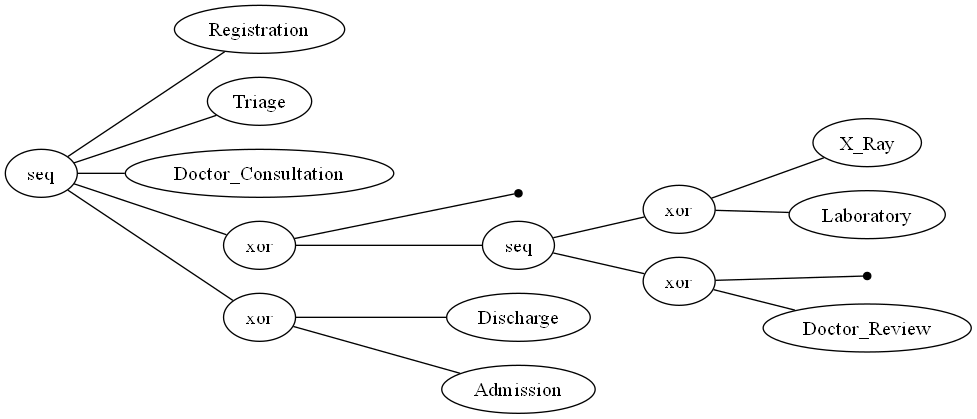

In [216]:
from pm4py import discover_process_tree_inductive

# Process tree discover karo
process_tree = discover_process_tree_inductive(event_log)

# Process tree display karo
pm4py.view_process_tree(process_tree)

In [217]:
print(process_tree)

->( 'Registration', 'Triage', 'Doctor_Consultation', X( tau, ->( X( 'X_Ray', 'Laboratory' ), X( tau, 'Doctor_Review' ) ) ), X( 'Discharge', 'Admission' ) )


In [218]:
print("Process discovery successful")
print("Process tree type:", type(process_tree))
print("Patient cases:", event_log["case:concept:name"].nunique())
print("Total events:", len(event_log))

Process discovery successful
Process tree type: <class 'pm4py.objects.process_tree.obj.ProcessTree'>
Patient cases: 500
Total events: 2607


In [109]:
import shutil
print(shutil.which("dot"))

C:\Program Files\Graphviz\bin\dot.EXE


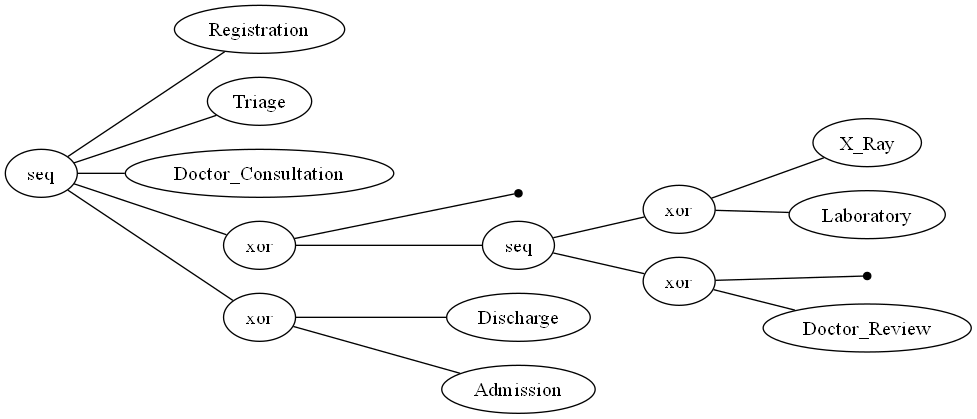

In [110]:
from pm4py.visualization.process_tree import visualizer

gviz = visualizer.apply(process_tree)
visualizer.view(gviz)

In [220]:

activity_delay = (
    event_clean
    .groupby("Activity_Name")["Gap_Minutes_From_Previous_Activity"]
    .agg(["mean", "median", "max", "count"])
    .round(2)
    .sort_values("mean", ascending=False)
)

activity_delay


,mean,median,max,count
Activity_Name,,,,
Admission,50.51,33.0,162.0,74
Laboratory,32.45,31.0,88.0,212
X_Ray,32.30,30.0,91.0,139
Doctor_Consultation,31.21,29.0,102.0,500
Doctor_Review,25.85,24.0,71.0,256
Discharge,25.17,25.0,49.0,426
Triage,12.63,13.0,25.0,500
Registration,NaN,NaN,NaN,0


In [221]:
top_5_delays = activity_delay.head(5)
top_5_delays

,mean,median,max,count
Activity_Name,,,,
Admission,50.51,33.0,162.0,74
Laboratory,32.45,31.0,88.0,212
X_Ray,32.30,30.0,91.0,139
Doctor_Consultation,31.21,29.0,102.0,500
Doctor_Review,25.85,24.0,71.0,256


In [222]:
activity_delay.to_csv("activity_delay_analysis.csv")

In [224]:
top_5_delays.to_csv("top_5_delays.csv")

In [225]:
print(process_tree)

->( 'Registration', 'Triage', 'Doctor_Consultation', X( tau, ->( X( 'X_Ray', 'Laboratory' ), X( tau, 'Doctor_Review' ) ) ), X( 'Discharge', 'Admission' ) )


In [227]:
activity_flow = (
    event_clean
    .groupby("Case_ID")["Activity_Name"]
    .apply(lambda x: " → ".join(x))
)

pathway_counts = activity_flow.value_counts()

pathway_counts.head(10)

Activity_Name
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge    129
Registration → Triage → Doctor_Consultation → Discharge                                 125
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge          87
Registration → Triage → Doctor_Consultation → Laboratory → Discharge                     58
Registration → Triage → Doctor_Consultation → X_Ray → Discharge                          27
Registration → Triage → Doctor_Consultation → Admission                                  24
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Admission          21
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission     19
Registration → Triage → Doctor_Consultation → Laboratory → Admission                      6
Registration → Triage → Doctor_Consultation → X_Ray → Admission                           4
Name: count, dtype: int64

In [229]:
# Har patient ka first aur last activity
patient_routes = (
    event_clean
    .sort_values(["Case_ID", "Timestamp"])
    .groupby("Case_ID")["Activity_Name"]
    .agg(["first", "last"])
)

# Validation checks
print("Total patients:", len(patient_routes))

print("\nStarting activity check:")
print(patient_routes["first"].value_counts())

print("\nEnding activity check:")
print(patient_routes["last"].value_counts())

print("\nPatients not starting with Registration:",
      (patient_routes["first"] != "Registration").sum())

print("\nPatients not ending with Discharge or Admission:",
      (~patient_routes["last"].isin(["Discharge", "Admission"])).sum())

Total patients: 500

Starting activity check:
first
Registration    500
Name: count, dtype: int64

Ending activity check:
last
Discharge    426
Admission     74
Name: count, dtype: int64

Patients not starting with Registration: 0

Patients not ending with Discharge or Admission: 0


In [230]:
pathway_analysis = pathway_counts.to_frame(
    name="Patient_Count"
)

pathway_analysis["Percentage"] = (
    pathway_analysis["Patient_Count"] / len(activity_flow) * 100
).round(2)

pathway_analysis.head(10)

,Patient_Count,Percentage
Activity_Name,,
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge,129,25.8
Registration → Triage → Doctor_Consultation → Discharge,125,25.0
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge,87,17.4
Registration → Triage → Doctor_Consultation → Laboratory → Discharge,58,11.6
Registration → Triage → Doctor_Consultation → X_Ray → Discharge,27,5.4
Registration → Triage → Doctor_Consultation → Admission,24,4.8
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Admission,21,4.2
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission,19,3.8
Registration → Triage → Doctor_Consultation → Laboratory → Admission,6,1.2


In [232]:
import pandas as pd

# Prepare event data
events_day2 = event_clean.copy()

events_day2["Timestamp"] = pd.to_datetime(
    events_day2["Timestamp"]
)

# Sort events in chronological order
events_day2 = events_day2.sort_values(
    ["Case_ID", "Timestamp"]
)

# Create one summary row per patient
patient_summary = (
    events_day2.groupby("Case_ID")
    .agg(
        Start_Time=("Timestamp", "first"),
        End_Time=("Timestamp", "last"),
        Pathway=(
            "Activity_Name",
            lambda x: " → ".join(x)
        )
    )
)

# Calculate total journey duration in minutes
patient_summary["Journey_Duration_Minutes"] = (
    patient_summary["End_Time"] -
    patient_summary["Start_Time"]
).dt.total_seconds() / 60

# Compare duration for each pathway
pathway_duration = (
    patient_summary.groupby("Pathway")
    .agg(
        Patient_Count=("Journey_Duration_Minutes", "count"),
        Mean_Duration=("Journey_Duration_Minutes", "mean"),
        Median_Duration=("Journey_Duration_Minutes", "median"),
        Max_Duration=("Journey_Duration_Minutes", "max")
    )
    .round(2)
    .sort_values("Mean_Duration", ascending=False)
)

pathway_duration

,Patient_Count,Mean_Duration,Median_Duration,Max_Duration
Pathway,,,,
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Admission,19,150.32,138.0,239.0
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Admission,21,147.62,136.0,260.0
Registration → Triage → Doctor_Consultation → Laboratory → Admission,6,142.17,136.5,238.0
Registration → Triage → Doctor_Consultation → Laboratory → Doctor_Review → Discharge,129,129.57,128.0,209.0
Registration → Triage → Doctor_Consultation → X_Ray → Doctor_Review → Discharge,87,124.40,120.0,217.0
Registration → Triage → Doctor_Consultation → Laboratory → Discharge,58,104.66,104.5,149.0
Registration → Triage → Doctor_Consultation → X_Ray → Discharge,27,101.89,101.0,166.0
Registration → Triage → Doctor_Consultation → X_Ray → Admission,4,95.50,98.0,109.0
Registration → Triage → Doctor_Consultation → Admission,24,93.75,83.5,207.0


In [233]:
patient_summary["Outcome"] = patient_summary["Pathway"].apply(
    lambda x: "Admission"
    if x.endswith("Admission")
    else "Discharge"
)

outcome_duration = (
    patient_summary
    .groupby("Outcome")["Journey_Duration_Minutes"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

outcome_duration

,count,mean,median,max
Outcome,,,,
Admission,74,127.58,117.5,260.0
Discharge,426,105.46,108.0,217.0


In [234]:
pathway_analysis.to_csv("patient_pathway_analysis.csv")
pathway_duration.to_csv("pathway_duration_analysis.csv")
outcome_duration.to_csv("admission_discharge_comparison.csv")
patient_summary.to_csv("patient_journey_summary.csv")

print("CareFlow Day 2 advanced analysis saved!")

CareFlow Day 2 advanced analysis saved!


In [236]:
print("Dataset Shape:", event_clean.shape)
print("\nColumns:")
print(event_clean.columns.tolist())

print("\nFirst 5 Rows:")
display(event_clean.head())

print("\nMissing Values:")
print(event_clean.isnull().sum())

Dataset Shape: (2607, 11)

Columns:
['Case_ID', 'Activity_Name', 'Timestamp', 'Doctor_ID', 'Department', 'Previous_Activity', 'Previous_Timestamp', 'Gap_Minutes_From_Previous_Activity', 'Expected_Previous_Activity', 'Expected_Previous_Timestamp', 'Expected_Gap_Minutes']

First 5 Rows:


,Case_ID,Activity_Name,Timestamp,Doctor_ID,Department,Previous_Activity,Previous_Timestamp,Gap_Minutes_From_Previous_Activity,Expected_Previous_Activity,Expected_Previous_Timestamp,Expected_Gap_Minutes
0,P0001,Registration,2026-10-01 18:39:00,NaN,Registration,NaN,NaT,NaN,NaN,NaT,NaN
1,P0001,Triage,2026-10-01 18:50:00,NaN,Emergency,Registration,2026-10-01 18:39:00,11.0,Registration,2026-10-01 18:39:00,11.0
2,P0001,Doctor_Consultation,2026-10-01 19:17:00,D11,Emergency,Triage,2026-10-01 18:50:00,27.0,Triage,2026-10-01 18:50:00,27.0
3,P0001,Laboratory,2026-10-01 19:44:00,NaN,Laboratory,Doctor_Consultation,2026-10-01 19:17:00,27.0,Doctor_Consultation,2026-10-01 19:17:00,27.0
4,P0001,Discharge,2026-10-01 20:25:00,D11,Emergency,Laboratory,2026-10-01 19:44:00,41.0,Laboratory,2026-10-01 19:44:00,41.0



Missing Values:
Case_ID                                  0
Activity_Name                            0
Timestamp                                0
Doctor_ID                             1425
Department                               0
Previous_Activity                      500
Previous_Timestamp                     500
Gap_Minutes_From_Previous_Activity     500
Expected_Previous_Activity             500
Expected_Previous_Timestamp            500
Expected_Gap_Minutes                   500
dtype: int64


In [240]:
# 1. Har patient ke events chronological order mein hain?
timestamp_check = (
    event_clean.groupby("Case_ID")["Timestamp"]
    .apply(lambda x: x.is_monotonic_increasing)
)

# 2. Previous activity match ho rahi hai?
activity_check = (
    event_clean["Previous_Activity"]
    .eq(event_clean["Expected_Previous_Activity"])
    | (
        event_clean["Previous_Activity"].isna()
        & event_clean["Expected_Previous_Activity"].isna()
    )
)

# 3. Previous timestamp match ho raha hai?
time_check = (
    event_clean["Previous_Timestamp"]
    .eq(event_clean["Expected_Previous_Timestamp"])
    | (
        event_clean["Previous_Timestamp"].isna()
        & event_clean["Expected_Previous_Timestamp"].isna()
    )
)

# 4. Gap minutes match ho rahe hain?
gap_check = (
    event_clean["Gap_Minutes_From_Previous_Activity"]
    .eq(event_clean["Expected_Gap_Minutes"])
    | (
        event_clean["Gap_Minutes_From_Previous_Activity"].isna()
        & event_clean["Expected_Gap_Minutes"].isna()
    )
)

print("All cases chronological:", timestamp_check.all())
print("Activity sequence matches:", activity_check.all())
print("Previous timestamps match:", time_check.all())
print("Gap calculations match:", gap_check.all())

print("\nFirst event missing previous activity:",
      event_clean.groupby("Case_ID")["Previous_Activity"]
      .first().isna().sum())

print("Unique patient cases:", event_clean["Case_ID"].nunique())

All cases chronological: True
Activity sequence matches: True
Previous timestamps match: True
Gap calculations match: True

First event missing previous activity: 0
Unique patient cases: 500


In [241]:
# Har patient ki actual first event row select karo
first_events = event_clean[
    event_clean.groupby("Case_ID").cumcount() == 0
]

print("Total first events:", len(first_events))

print(
    "First events with missing previous activity:",
    first_events["Previous_Activity"].isna().sum()
)

print(
    "First events with missing previous timestamp:",
    first_events["Previous_Timestamp"].isna().sum()
)

print(
    "First events with missing gap:",
    first_events["Gap_Minutes_From_Previous_Activity"].isna().sum()
)

Total first events: 500
First events with missing previous activity: 500
First events with missing previous timestamp: 500
First events with missing gap: 500


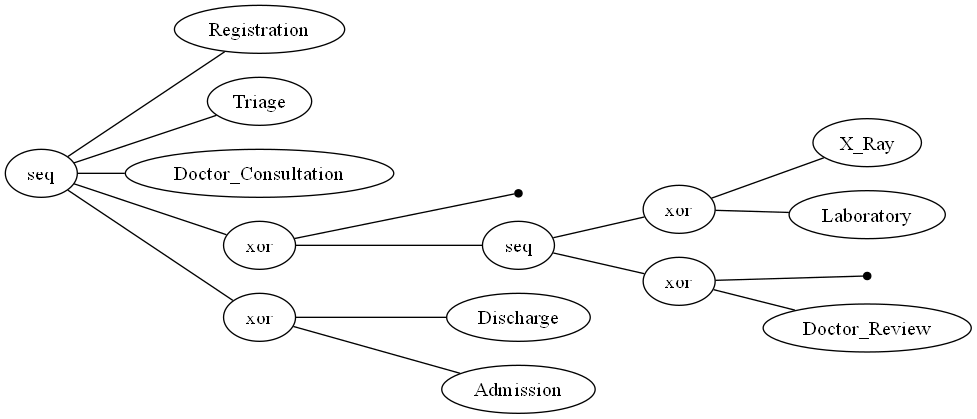

In [242]:
import pm4py

# Process tree ko graphical diagram mein convert karo
pm4py.view_process_tree(process_tree)

In [243]:
pm4py.save_vis_process_tree(
    process_tree,
    "careflow_process_tree.png"
)

''

In [244]:
import os

print("Current Folder:", os.getcwd())
print("\nProject Files:")
for file in os.listdir():
    print(file)

Current Folder: C:\Users\HP\dataproject

Project Files:
.ipynb_checkpoints
activity_delay_analysis.csv
admission_discharge_comparison.csv
appointments.csv
appointments_registration.csv
appointments_registration_cleaned.csv
billing.csv
careflow_process_tree.png
customer_master.csv
doctors.csv
doctors_master.csv
doctor_status_log.csv
ecommerce_sales_customer_analytics_150k.csv
healthcare_project.ipynb
operational_factors.csv
pathway_duration_analysis.csv
patient.csv
patients.csv
patient_event_log.csv
patient_journey_summary.csv
patient_pathway_analysis.csv
project1.ipynb
top_5_delays.csv
treatments.csv
Untitled.ipynb
Untitled1.ipynb
Untitled2.ipynb


In [245]:
import os
import subprocess

# Git repository status
result = subprocess.run(
    ["git", "rev-parse", "--show-toplevel"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("Git Repository:", result.stdout.strip())

    status = subprocess.run(
        ["git", "status", "--short"],
        capture_output=True,
        text=True
    )
    print("\nGit Status:")
    print(status.stdout if status.stdout else "No uncommitted changes")
else:
    print("Current folder Git repository nahi hai.")

# Pipeline-related files
print("\nPipeline-related files:")
for f in os.listdir():
    if f.endswith((".sql", ".yml", ".yaml", ".py")):
        print(f)

Current folder Git repository nahi hai.

Pipeline-related files:


In [247]:
import os

base = os.path.expanduser("~")
search_folders = ["Desktop", "Documents", "Downloads", "PycharmProjects", "source"]

for folder in search_folders:
    path = os.path.join(base, folder)

    if not os.path.isdir(path):
        continue

    for root, dirs, files in os.walk(path):
        dirs[:] = [d for d in dirs if d not in [
            "node_modules", ".ipynb_checkpoints", "__pycache__"
        ]]

        if ".git" in dirs:
            print("Git Repository:", root)
            dirs.remove(".git")

In [248]:
copy C:\Users\HP\dataproject\healthcare_project.ipynb C:\Users\HP\CareFlow-Repo\

        1 file(s) copied.


In [251]:
# Calculate total journey time for each patient
journey_time = (
    event_clean.groupby("Case_ID")["Timestamp"]
    .agg(Start_Time="min", End_Time="max")
    .reset_index()
)

journey_time["Total_Journey_Minutes"] = (
    journey_time["End_Time"] - journey_time["Start_Time"]
).dt.total_seconds() / 60

# Combine journey time with operational factors
delay_analysis = journey_time[
    ["Case_ID", "Total_Journey_Minutes"]
].merge(op, on="Case_ID", how="left")

# Compare journey time by doctor availability
print("Doctor Status vs Patient Journey Time")
print(
    delay_analysis.groupby("Doctor_Status_At_Consult_Start")
    ["Total_Journey_Minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

# Compare journey time by queue length
delay_analysis["Queue_Group"] = pd.cut(
    delay_analysis["Queue_Length_At_Triage"],
    bins=[-1, 3, 6, 10, float("inf")],
    labels=["0–3", "4–6", "7–10", "11+"]
)

print("\nQueue Length vs Patient Journey Time")
print(
    delay_analysis.groupby("Queue_Group", observed=False)
    ["Total_Journey_Minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

# Compare journey time by staff status
print("\nStaff Status vs Patient Journey Time")
print(
    delay_analysis.groupby("Staff_Status")
    ["Total_Journey_Minutes"]
    .agg(["count", "mean", "median"])
    .round(2)
)

Doctor Status vs Patient Journey Time
                                count    mean  median
Doctor_Status_At_Consult_Start                       
Available                         145   97.59    99.0
Busy                              355  113.28   114.0

Queue Length vs Patient Journey Time
             count    mean  median
Queue_Group                       
0–3            112   98.29    95.5
4–6            231  109.96   109.0
7–10           144  113.33   115.5
11+             13  126.00   126.0

Staff Status vs Patient Journey Time
               count    mean  median
Staff_Status                        
Adequate         419  108.62   108.0
Short_Staffed     81  109.30   109.0


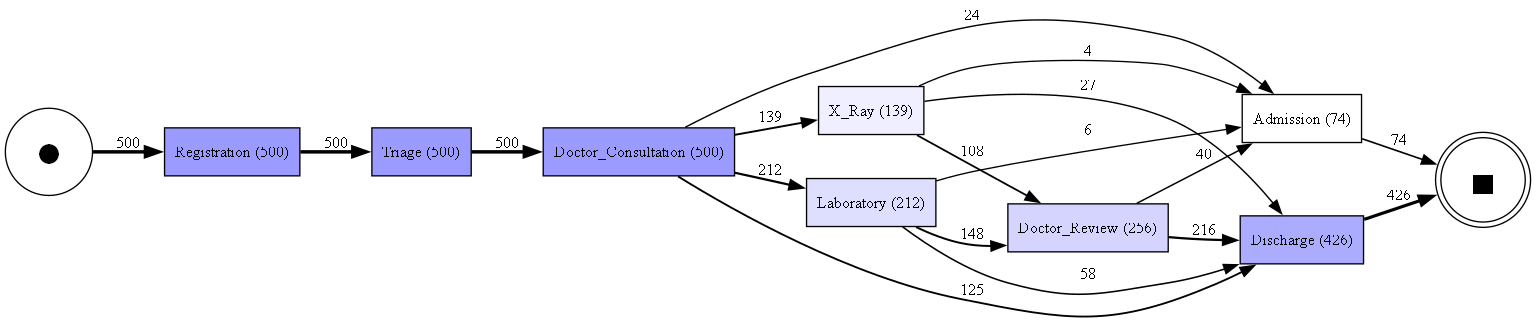

In [256]:

import pm4py
# Prepare the required columns for PM4Py
df_dfg = event_clean[
    ["Case_ID", "Activity_Name", "Timestamp"]
].copy()

df_dfg = df_dfg.rename(columns={
    "Case_ID": "case:concept:name",
    "Activity_Name": "concept:name",
    "Timestamp": "time:timestamp"
})

df_dfg["time:timestamp"] = pd.to_datetime(
    df_dfg["time:timestamp"]
)

# Discover and display DFG
dfg, start_activities, end_activities = pm4py.discover_dfg(
    df_dfg,
    case_id_key="case:concept:name",
    activity_key="concept:name",
    timestamp_key="time:timestamp"
)

pm4py.view_dfg(dfg, start_activities, end_activities)


In [257]:
print(event_clean["Activity_Name"].value_counts())

Activity_Name
Registration           500
Triage                 500
Doctor_Consultation    500
Discharge              426
Doctor_Review          256
Laboratory             212
X_Ray                  139
Admission               74
Name: count, dtype: int64


In [259]:
# Check the activity names used to create the DFG
print(df_dfg["concept:name"].value_counts())

# Check the actual activity labels in the graph
print(sorted(set(
    activity
    for pair in dfg.keys()
    for activity in pair
)))

concept:name
Registration           500
Triage                 500
Doctor_Consultation    500
Discharge              426
Doctor_Review          256
Laboratory             212
X_Ray                  139
Admission               74
Name: count, dtype: int64
['Admission', 'Discharge', 'Doctor_Consultation', 'Doctor_Review', 'Laboratory', 'Registration', 'Triage', 'X_Ray']


In [260]:

pm4py.save_vis_dfg(
    dfg,
    start_activities,
    end_activities,
    file_path="careflow_dfg.png"
)

print("DFG saved successfully as careflow_dfg.png")


DFG saved successfully as careflow_dfg.png


In [261]:

import os
print("Current folder:", os.getcwd())
print("DFG file exists:", os.path.exists("careflow_dfg.png"))
print("File path:", os.path.abspath("careflow_dfg.png"))


Current folder: C:\Users\HP\dataproject
DFG file exists: True
File path: C:\Users\HP\dataproject\careflow_dfg.png


In [262]:

import shutil
import os

source = r"C:\Users\HP\dataproject\careflow_dfg.png"
destination = r"C:\Users\HP\CareFlow-Repo\careflow_dfg.png"

shutil.copy2(source, destination)

print("File copied:", os.path.exists(destination))
print("Saved at:", destination)


File copied: True
Saved at: C:\Users\HP\CareFlow-Repo\careflow_dfg.png


In [265]:
import pandas as pd

# 1. Triage aur Doctor Consultation timestamps
triage = event_clean[
    event_clean["Activity_Name"] == "Triage"
][["Case_ID", "Timestamp"]].rename(
    columns={"Timestamp": "Triage_Timestamp"}
)

consult = event_clean[
    event_clean["Activity_Name"] == "Doctor_Consultation"
][["Case_ID", "Timestamp", "Doctor_ID"]].rename(
    columns={"Timestamp": "Consultation_Timestamp"}
)

# 2. Patient ka waiting gap calculate karo
waiting = triage.merge(consult, on="Case_ID")

waiting["Waiting_Minutes"] = (
    waiting["Consultation_Timestamp"] - waiting["Triage_Timestamp"]
).dt.total_seconds() / 60

# 3. Doctor status log se consultation duration nikalo
status_times = doc.pivot_table(
    index=["Case_ID", "Doctor_ID"],
    columns="Status",
    values="Timestamp",
    aggfunc="min"
).reset_index()

status_times = status_times.rename(columns={
    "In_Consultation": "Consultation_Start",
    "Available": "Doctor_Available_Time"
})

status_times["Consultation_Start"] = pd.to_datetime(
    status_times["Consultation_Start"]
)
status_times["Doctor_Available_Time"] = pd.to_datetime(
    status_times["Doctor_Available_Time"]
)

status_times["Consultation_Duration_Minutes"] = (
    status_times["Doctor_Available_Time"] -
    status_times["Consultation_Start"]
).dt.total_seconds() / 60

# 4. Dono datasets compare karo
comparison = waiting.merge(
    status_times,
    on=["Case_ID", "Doctor_ID"],
    how="left"
)

print("Total patients:", len(comparison))
print("Patients with consultation duration:",
      comparison["Consultation_Duration_Minutes"].notna().sum())

print("\nOverall summary:")
print(comparison[
    ["Waiting_Minutes", "Consultation_Duration_Minutes"]
].describe().round(2))

print("\nDoctor-wise summary:")
print(
    comparison.groupby("Doctor_ID")[
        ["Waiting_Minutes", "Consultation_Duration_Minutes"]
    ].mean().round(2)
)

comparison.head(10)

Total patients: 500
Patients with consultation duration: 500

Overall summary:
       Waiting_Minutes  Consultation_Duration_Minutes
count           500.00                         500.00
mean             31.21                          11.58
std              14.96                           4.60
min               4.00                           4.00
25%              21.00                           8.00
50%              29.00                          12.00
75%              39.00                          14.00
max             102.00                          27.00

Doctor-wise summary:
           Waiting_Minutes  Consultation_Duration_Minutes
Doctor_ID                                                
D01                  28.17                          11.28
D02                  30.92                          12.24
D03                  31.79                          12.75
D04                  32.29                          11.56
D05                  32.34                          10.90
D06    

,Case_ID,Triage_Timestamp,Consultation_Timestamp,Doctor_ID,Waiting_Minutes,Doctor_Available_Time,Consultation_Start,Consultation_Duration_Minutes
0,P0001,2026-10-01 18:50:00,2026-10-01 19:17:00,D11,27.0,2026-10-01 19:24:00,2026-10-01 19:17:00,7.0
1,P0002,2026-10-10 18:35:00,2026-10-10 19:07:00,D02,32.0,2026-10-10 19:19:00,2026-10-10 19:07:00,12.0
2,P0003,2026-10-03 08:38:00,2026-10-03 08:59:00,D05,21.0,2026-10-03 09:10:00,2026-10-03 08:59:00,11.0
3,P0004,2026-10-02 15:42:00,2026-10-02 16:08:00,D01,26.0,2026-10-02 16:22:00,2026-10-02 16:08:00,14.0
4,P0005,2026-10-03 08:23:00,2026-10-03 09:02:00,D06,39.0,2026-10-03 09:20:00,2026-10-03 09:02:00,18.0
5,P0006,2026-10-04 14:55:00,2026-10-04 15:41:00,D03,46.0,2026-10-04 15:52:00,2026-10-04 15:41:00,11.0
6,P0007,2026-10-02 15:41:00,2026-10-02 16:13:00,D01,32.0,2026-10-02 16:25:00,2026-10-02 16:13:00,12.0
7,P0008,2026-10-08 20:08:00,2026-10-08 20:32:00,D11,24.0,2026-10-08 20:42:00,2026-10-08 20:32:00,10.0
8,P0009,2026-10-10 08:22:00,2026-10-10 08:47:00,D06,25.0,2026-10-10 09:01:00,2026-10-10 08:47:00,14.0
9,P0010,2026-10-10 19:12:00,2026-10-10 19:36:00,D05,24.0,2026-10-10 19:57:00,2026-10-10 19:36:00,21.0


In [266]:
# Waiting-time categories
comparison["Waiting_Category"] = pd.cut(
    comparison["Waiting_Minutes"],
    bins=[-1, 15, 30, 45, float("inf")],
    labels=["0-15 min", "16-30 min", "31-45 min", "Above 45 min"]
)

print("Waiting time distribution:")
print(comparison["Waiting_Category"].value_counts().sort_index())

print("\nPatients waiting more than 30 minutes:")
print((comparison["Waiting_Minutes"] > 30).sum())

print("\nTop 10 longest waits:")
display(
    comparison[
        ["Case_ID", "Doctor_ID", "Waiting_Minutes",
         "Consultation_Duration_Minutes"]
    ]
    .sort_values("Waiting_Minutes", ascending=False)
    .head(10)
)

Waiting time distribution:
Waiting_Category
0-15 min         56
16-30 min       211
31-45 min       165
Above 45 min     68
Name: count, dtype: int64

Patients waiting more than 30 minutes:
233

Top 10 longest waits:


,Case_ID,Doctor_ID,Waiting_Minutes,Consultation_Duration_Minutes
221,P0222,D02,102.0,15.0
18,P0019,D05,95.0,19.0
10,P0011,D03,91.0,19.0
234,P0235,D04,87.0,9.0
494,P0495,D05,83.0,10.0
134,P0135,D11,81.0,8.0
95,P0096,D12,81.0,19.0
192,P0193,D05,74.0,4.0
154,P0155,D03,73.0,16.0
290,P0291,D11,70.0,14.0


In [267]:
# 1. Save patient-level delay analysis
comparison.to_csv("careflow_delay_analysis.csv", index=False)

# 2. Save waiting-time distribution
waiting_summary = (
    comparison["Waiting_Category"]
    .value_counts()
    .sort_index()
    .rename_axis("Waiting_Category")
    .reset_index(name="Patient_Count")
)

waiting_summary["Percentage"] = (
    waiting_summary["Patient_Count"] / len(comparison) * 100
).round(2)

waiting_summary.to_csv(
    "careflow_waiting_summary.csv", index=False
)

# 3. Save top 10 longest waiting cases
top_10_waits = comparison[
    ["Case_ID", "Doctor_ID", "Waiting_Minutes",
     "Consultation_Duration_Minutes"]
].nlargest(10, "Waiting_Minutes")

top_10_waits.to_csv("top_10_waiting_cases.csv", index=False)

print("Saved all 3 delay analysis files successfully.")

Saved all 3 delay analysis files successfully.


In [268]:
import os

print("Current folder:", os.getcwd())

for file in [
    "careflow_delay_analysis.csv",
    "careflow_waiting_summary.csv",
    "top_10_waiting_cases.csv"
]:
    print(file, "->", os.path.exists(file))

Current folder: C:\Users\HP\dataproject
careflow_delay_analysis.csv -> True
careflow_waiting_summary.csv -> True
top_10_waiting_cases.csv -> True


In [269]:
import os
print(os.getcwd())

C:\Users\HP\dataproject


In [3]:
# CareFlow Pipeline Audit

print("Total patient cases:", event_clean["Case_ID"].nunique())
print("Total events:", len(event_clean))

print("\nMissing values:")
print(event_clean[
    ["Case_ID", "Activity_Name", "Timestamp"]
].isnull().sum())

print("\nTimestamp data type:")
print(event_clean["Timestamp"].dtype)

print("\nEvents in chronological order within each patient:")
chronological = (
    event_clean.groupby("Case_ID")["Timestamp"]
    .apply(lambda s: s.is_monotonic_increasing)
)

print("All cases chronological:", chronological.all())

NameError: name 'event_clean' is not defined